**EXTRA**

Data period: 2009-01-01 00:00:00 to 2016-12-01 00:00:00
Number of monthly observations: 96
Training data: 2009-01-01 00:00:00 to 2015-12-01 00:00:00
Testing data: 2016-01-01 00:00:00 to 2016-12-01 00:00:00


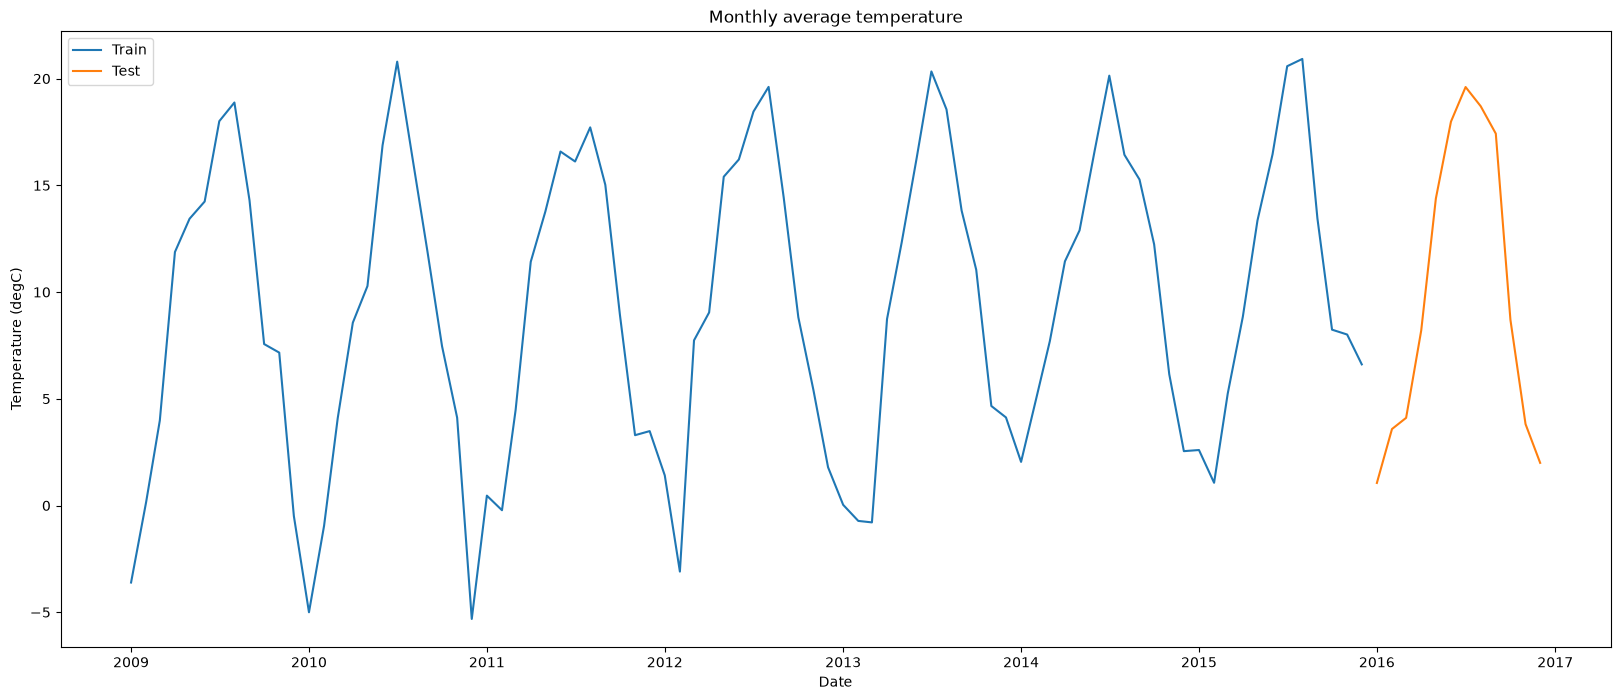

In [1]:
#data preparation
import pandas as pd
import numpy as np
from sklearn.metrics import root_mean_squared_error
from scipy.stats import boxcox
from scipy.special import inv_boxcox
from statsmodels.tsa.stattools import kpss
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.exponential_smoothing.ets import ETSModel
from matplotlib import pyplot as plt
%matplotlib inline

weather = pd.read_csv('../data/weather.csv')
weather['Date Time'] = pd.to_datetime(weather['Date Time'], format='%d.%m.%Y %H:%M:%S')

monthly_temp = weather.set_index('Date Time')['T (degC)'].resample('MS').mean()

monthly_temp = monthly_temp.reset_index()
monthly_temp.columns = ['year_month', 'temperature']

train = monthly_temp.iloc[:-12].copy()
test = monthly_temp.iloc[-12:].copy()

print('Data period:', monthly_temp['year_month'].min(), 'to', monthly_temp['year_month'].max())
print('Number of monthly observations:', len(monthly_temp))
print('Training data:', train['year_month'].min(), 'to', train['year_month'].max())
print('Testing data:', test['year_month'].min(), 'to', test['year_month'].max())

plt.figure(figsize = (20,8))
plt.plot(train['year_month'], train['temperature'], label = 'Train')
plt.plot(test['year_month'], test['temperature'], label = 'Test')
plt.legend(loc = 'upper left')
plt.title('Monthly average temperature')
plt.xlabel('Date')
plt.ylabel('Temperature (degC)')
plt.show()

The dataset contains 96 monthly observations from January 2009 to December 2016. Calculate the monthly average temperature using resampling. The last 12 months (2016) are kept as the test set; everything before is the train set.

In [2]:
#stationary?
kpss_stat, pval, lags, crit = kpss(train['temperature'], regression = 'c', nlags = 'legacy')
print('p Value to the KPSS test is: ', pval)

p Value to the KPSS test is:  0.02642357215447875


Because p-value is below 0.05, we consider the time series as non-stationary at a confidence level of 95%.

**to achieve stationarity**

0.930117883536739


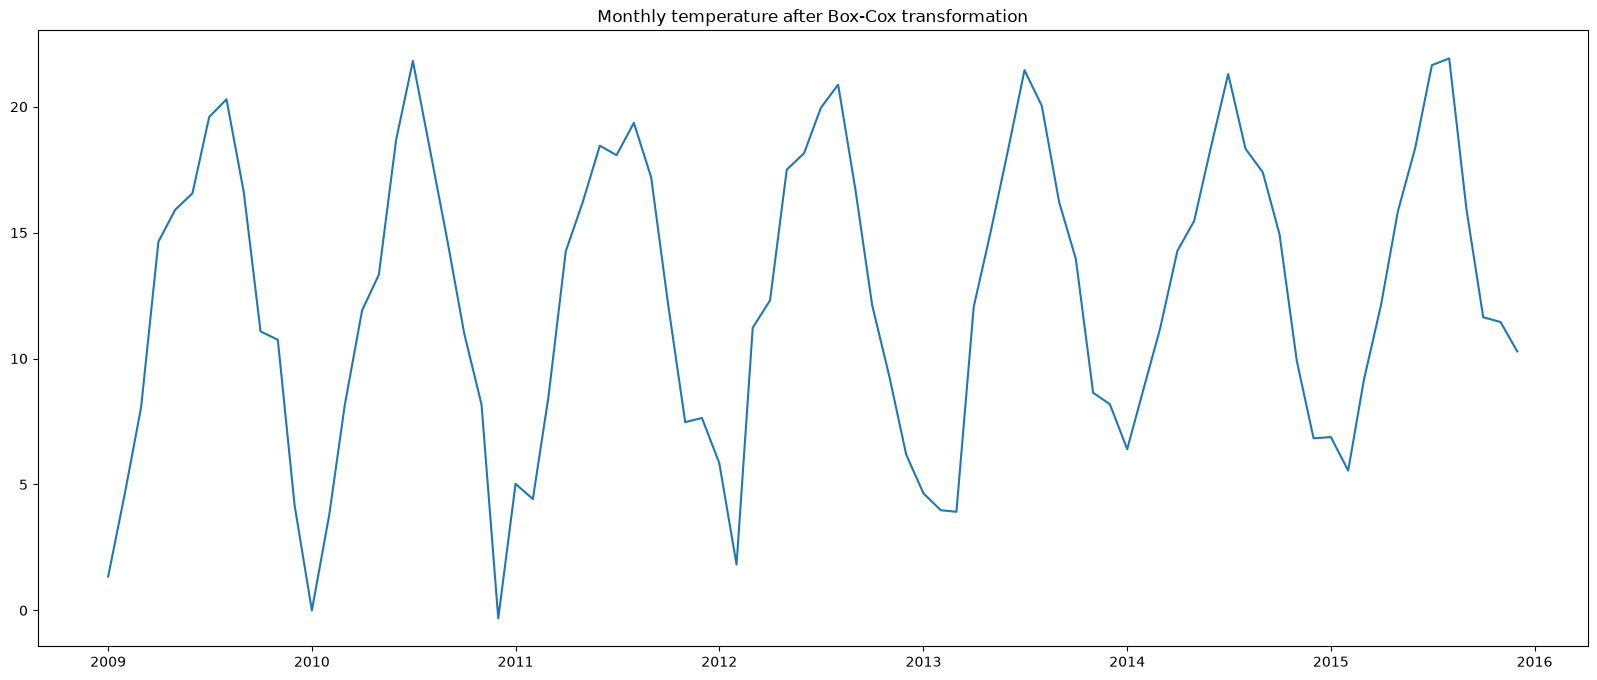

In [3]:
#Box-Cox
offset = 6.0
BC_train, lmbda = boxcox(train['temperature'] + offset)
train['temperature_BC'] = BC_train
test['temperature_BC'] = boxcox(test['temperature'] + offset, lmbda = lmbda)
print(lmbda)
plt.figure(figsize = (20,8))
plt.plot(train['year_month'], train['temperature_BC'])
plt.title('Monthly temperature after Box-Cox transformation')
plt.show()

The issue of increasing variance is alleviated. The time series data still exhibits an increasing trend and seasonality.

In [4]:
#de-seasonalise
train['month'] = train['year_month'].dt.month
test['month'] = test['year_month'].dt.month

temp_by_month = train.groupby('month')['temperature_BC'].mean().reset_index()
temp_by_month = temp_by_month.rename(columns = {'temperature_BC':'temperature_month_avg'})

train = train.merge(temp_by_month, on = 'month')
test = test.merge(temp_by_month, on = 'month')

train['temperature_de_season'] = train['temperature_BC'] - train['temperature_month_avg']
test['temperature_de_season'] = test['temperature_BC'] - test['temperature_month_avg']

train.head()

,year_month,temperature,temperature_BC,month,temperature_month_avg,temperature_de_season
0,2009-01-01,-3.608829,1.343749,1,4.305900,-2.962151
1,2009-02-01,0.172842,4.768816,2,4.749158,0.019659
2,2009-03-01,3.985013,8.065454,3,8.595569,-0.530115
3,2009-04-01,11.876306,14.636740,4,13.085317,1.551424
4,2009-05-01,13.434731,15.906989,5,15.602758,0.304232


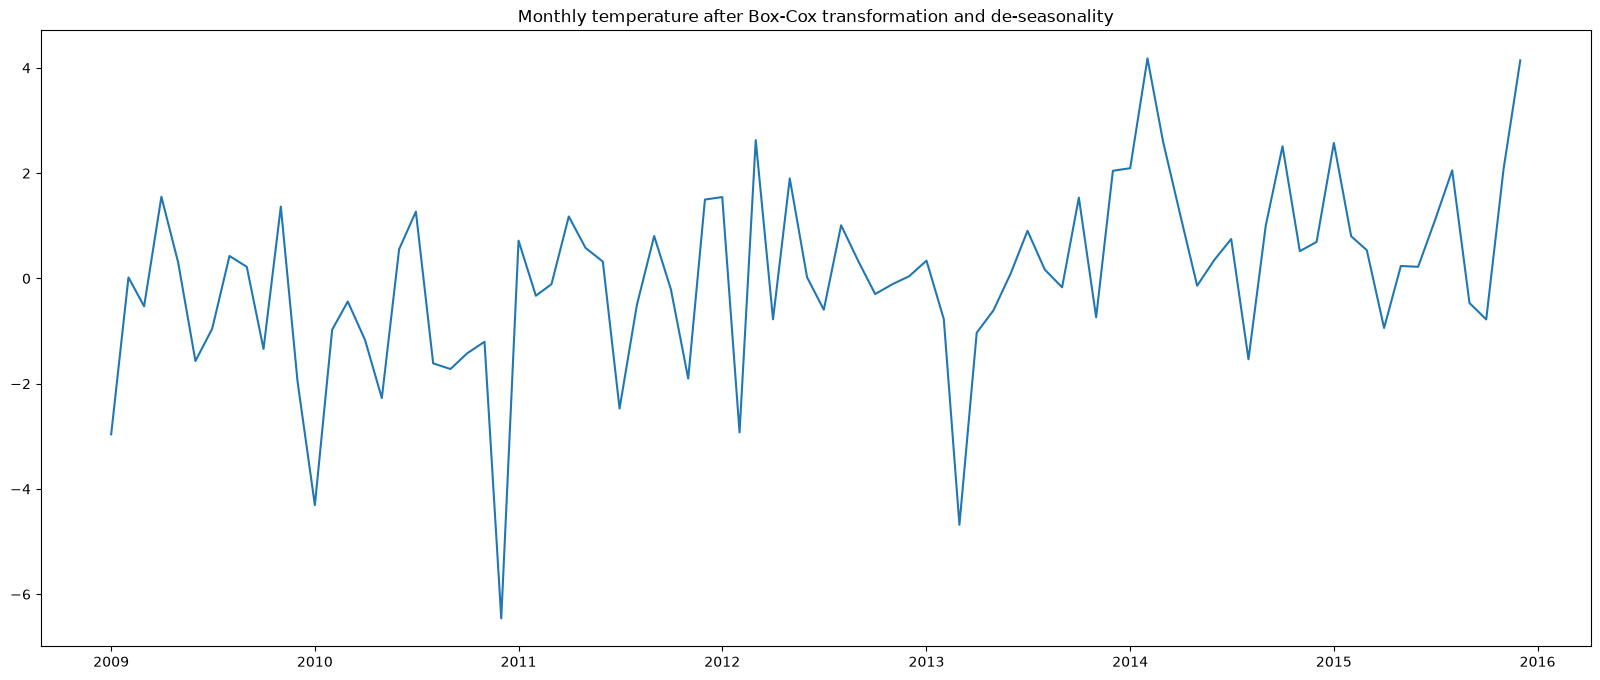

In [5]:
plt.figure(figsize = (20,8))
plt.plot(train['year_month'], train['temperature_de_season'])
plt.title('Monthly temperature after Box-Cox transformation and de-seasonality')
plt.show()

The seasonality is removed. The time series data has an increasing trend.

In [6]:
#de-trend
train['temperature_diff1'] = train['temperature_de_season'].diff()
train.head()

,year_month,temperature,temperature_BC,month,temperature_month_avg,temperature_de_season,temperature_diff1
0,2009-01-01,-3.608829,1.343749,1,4.305900,-2.962151,NaN
1,2009-02-01,0.172842,4.768816,2,4.749158,0.019659,2.981810
2,2009-03-01,3.985013,8.065454,3,8.595569,-0.530115,-0.549774
3,2009-04-01,11.876306,14.636740,4,13.085317,1.551424,2.081539
4,2009-05-01,13.434731,15.906989,5,15.602758,0.304232,-1.247192


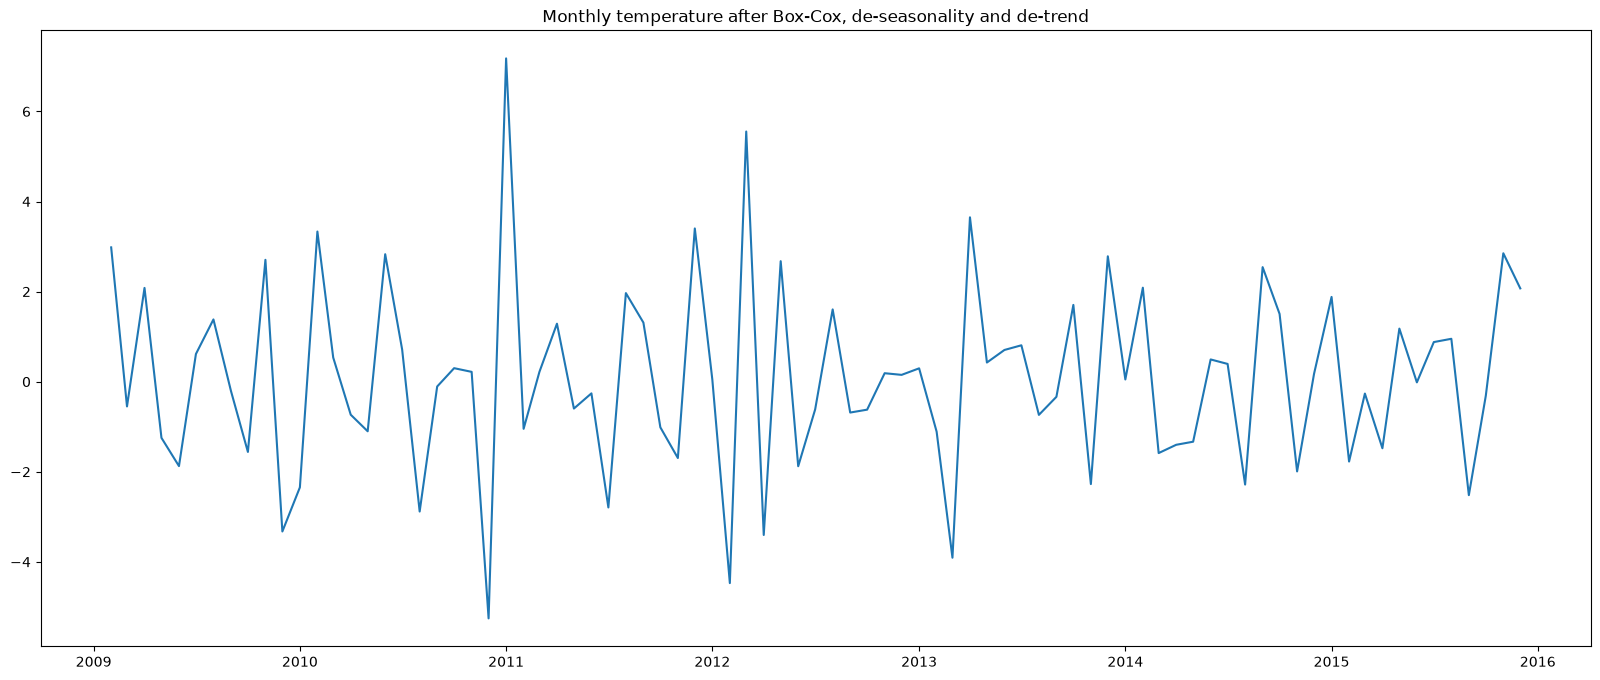

In [7]:
plt.figure(figsize = (20,8))
plt.plot(train['year_month'], train['temperature_diff1'])
plt.title('Monthly temperature after Box-Cox, de-seasonality and de-trend')
plt.show()

In [8]:
_, pval, __, ___ = kpss(train['temperature_diff1'][1:], regression = 'c', nlags = 'legacy') # do not include the first NaN value
print('p Value to the KPSS test is: ', pval)

p Value to the KPSS test is:  0.1


C:\Users\李斌楠\AppData\Local\Temp\ipykernel_23720\2992549487.py:1: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is greater than the p-value returned.

  _, pval, __, ___ = kpss(train['temperature_diff1'][1:], regression = 'c', nlags = 'legacy') # do not include the first NaN value


Because p-value is above 0.05, we consider the time series as stationary at a confidence level of 95%.

**ARIMA**

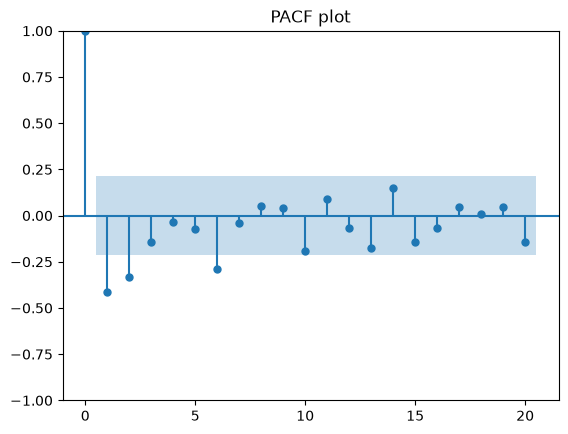

In [9]:
#Use the PACF plot to find the order (i.e. p) of autoregression (AR).
plot_pacf(train['temperature_diff1'][1:], title = 'PACF plot');
plt.show()

The first two lags are significant and a simpler model is preferred.

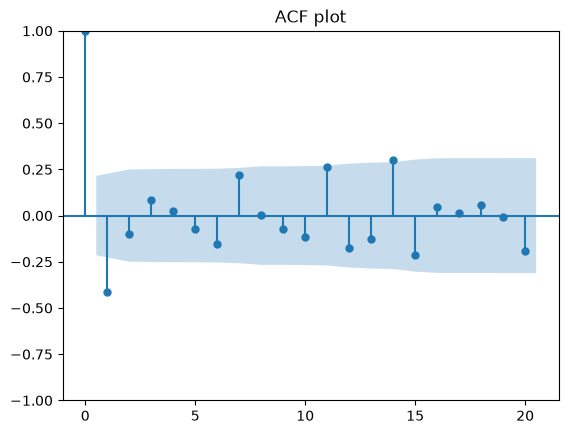

In [10]:
#Use the ACF plot to find the order (i.e. q) of moving average (MA).
plot_acf(train['temperature_diff1'][1:], title = 'ACF plot');
plt.show()

Only the first lag is clearly significant.

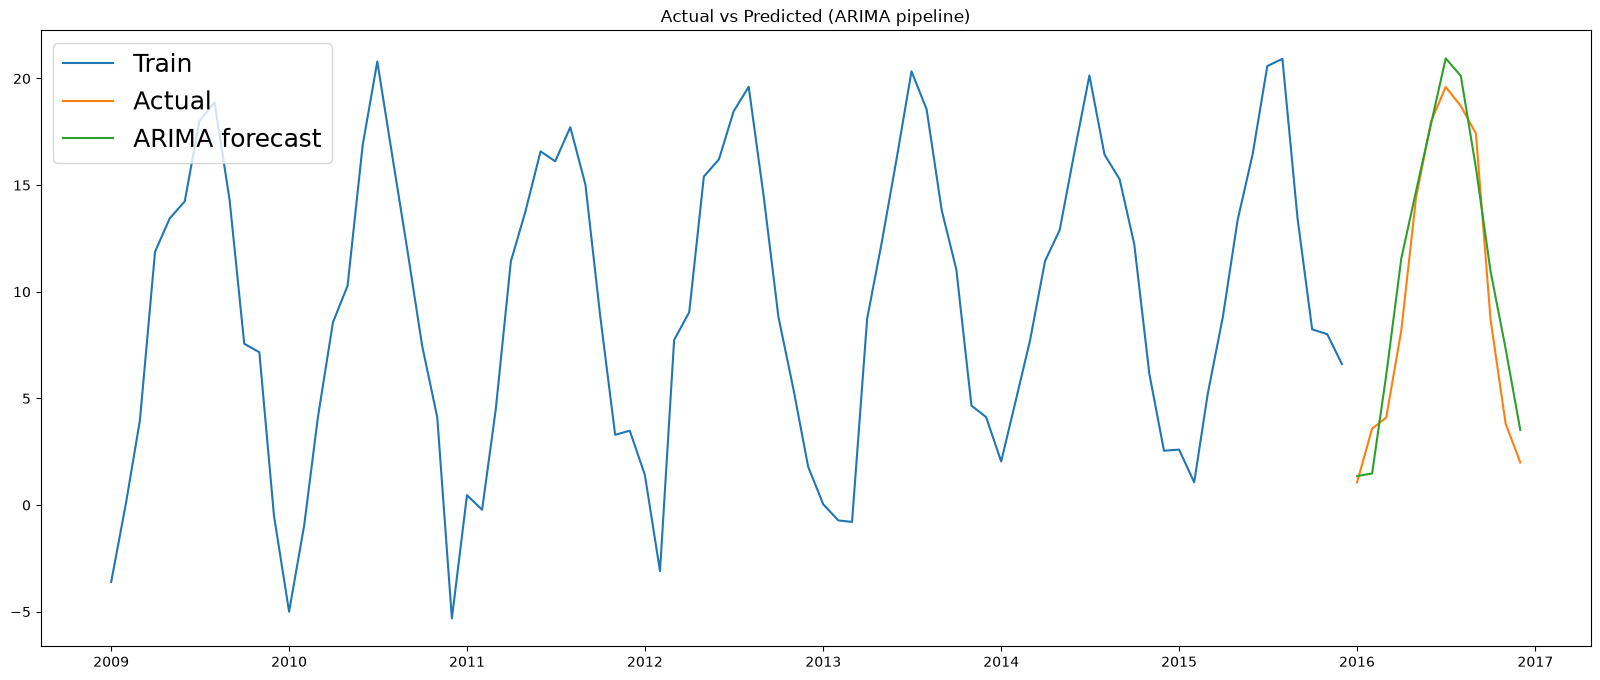

In [11]:
model = ARIMA(train['temperature_diff1'][1:], order = (2,0,1))
model_fit = model.fit()
d_predict = model_fit.forecast(12)

last_de_season = train['temperature_de_season'].iloc[-1]
de_season_pred = last_de_season + np.cumsum(d_predict.to_numpy())
BC_pred = de_season_pred + test['temperature_month_avg'].to_numpy()
y_predict = inv_boxcox(BC_pred, lmbda) - offset

plt.figure(figsize = (20,8))
plt.plot(train['year_month'], train['temperature'], label = 'Train')
plt.plot(test['year_month'], test['temperature'], label = 'Actual')
plt.plot(test['year_month'], y_predict, label = 'ARIMA forecast')
plt.title('Actual vs Predicted (ARIMA pipeline)')
plt.legend(loc = 'upper left', fontsize = 18)
plt.show()

In [12]:
rmse_arima = root_mean_squared_error(y_true = test['temperature'], y_pred = y_predict)
print('ARIMA RMSE: ', rmse_arima)

ARIMA RMSE:  1.959464365749291


**ETS**

As in the tutorial, ETS is fitted on the Box-Cox series, then the forecast is inverted back to degrees Celsius. I use ETS with an additive trend and additive seasonality. The seasonal period is set to 12 because the data contains monthly observations and yearly seasonality.

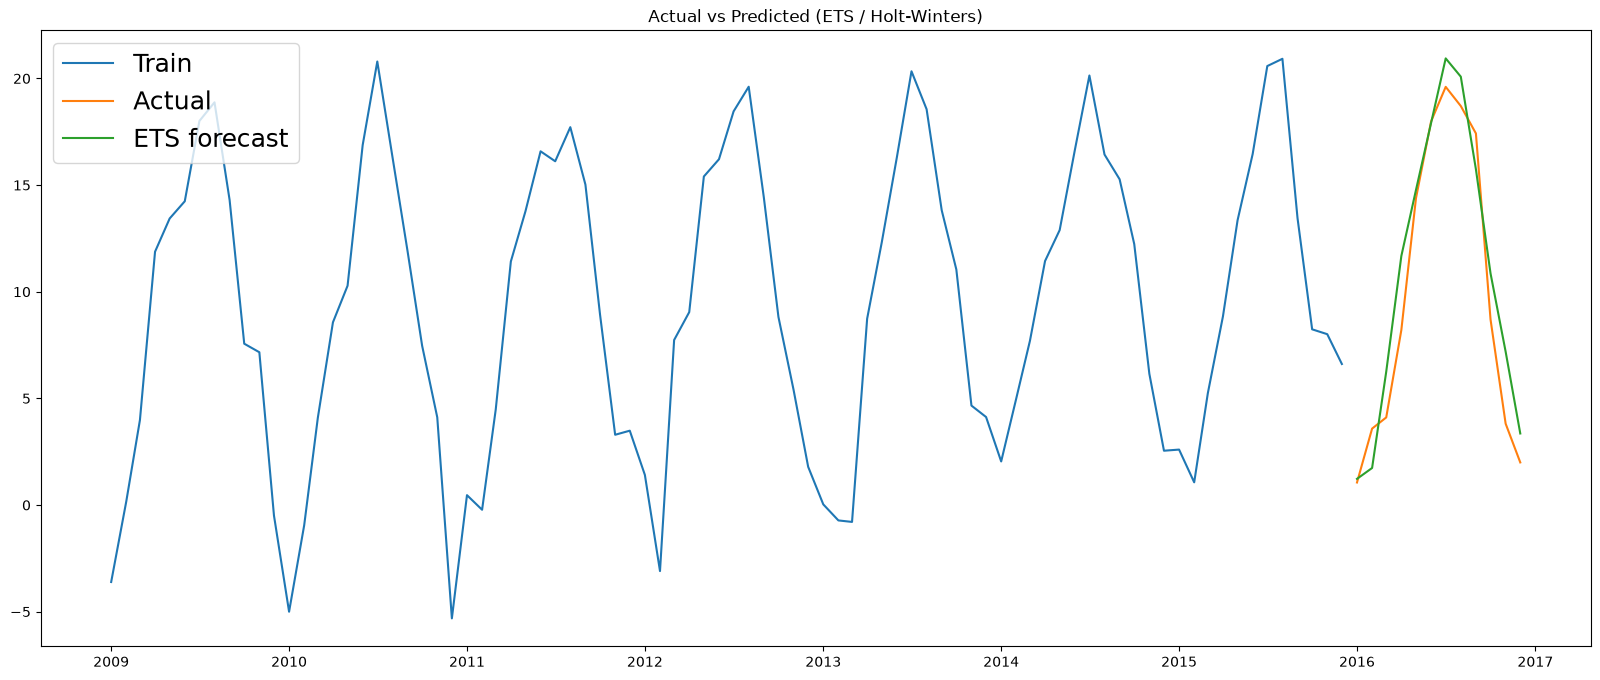

In [13]:
hw = ETSModel(train['temperature_BC'], trend = 'add', seasonal = 'add', seasonal_periods = 12)
hw_fit = hw.fit()
BC_pred_ets = hw_fit.forecast(12)
y_predict_ets = inv_boxcox(BC_pred_ets.to_numpy(), lmbda) - offset

plt.figure(figsize = (20,8))
plt.plot(train['year_month'], train['temperature'], label = 'Train')
plt.plot(test['year_month'], test['temperature'], label = 'Actual')
plt.plot(test['year_month'], y_predict_ets, label = 'ETS forecast')
plt.title('Actual vs Predicted (ETS / Holt-Winters)')
plt.legend(loc = 'upper left', fontsize = 18)
plt.show()

In [14]:
rmse_ets = root_mean_squared_error(y_true = test['temperature'], y_pred = y_predict_ets)
print('ETS RMSE: ', rmse_ets)

ETS RMSE:  1.9287916114226513


**Evaluation**

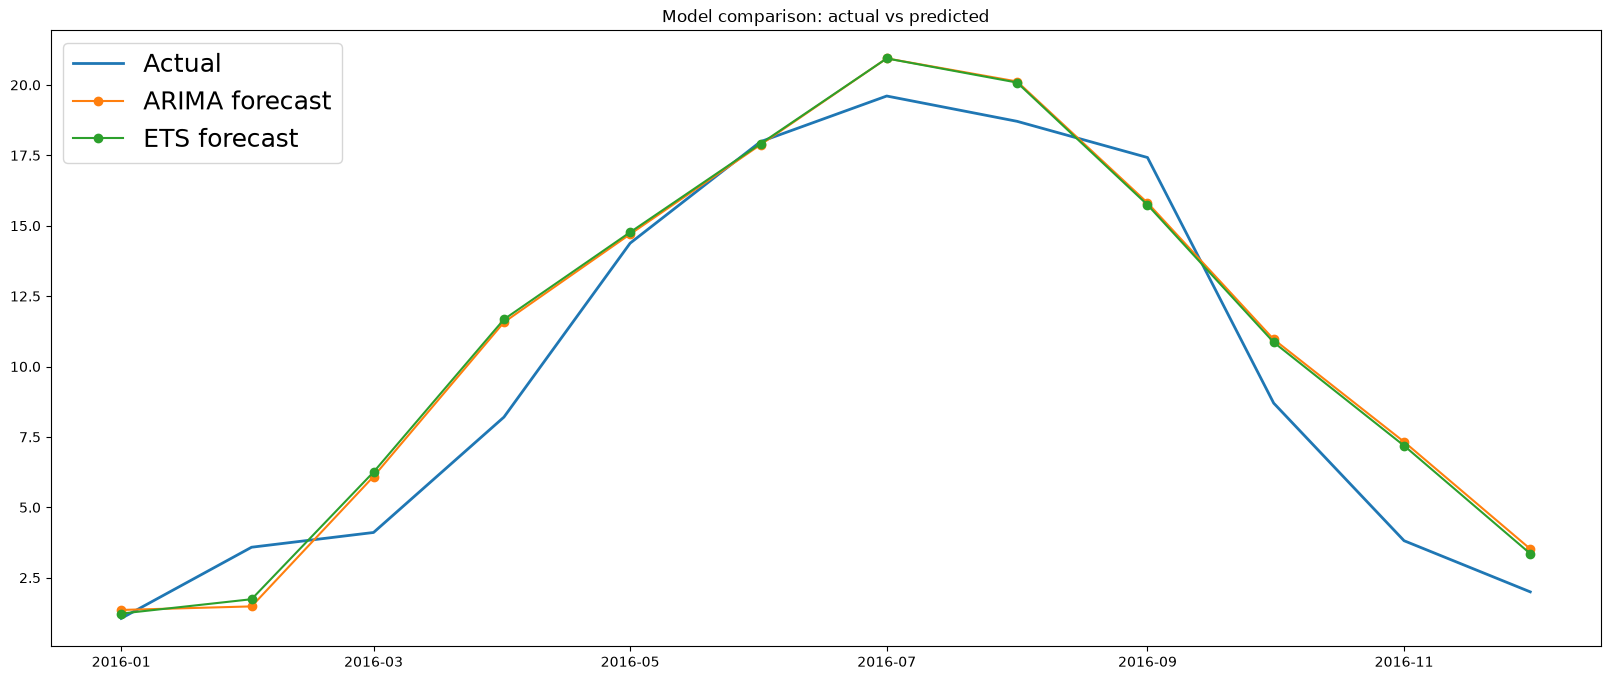

In [15]:
plt.figure(figsize = (20,8))
plt.plot(test['year_month'], test['temperature'], label = 'Actual', linewidth = 2)
plt.plot(test['year_month'], y_predict, label = 'ARIMA forecast', marker = 'o')
plt.plot(test['year_month'], y_predict_ets, label = 'ETS forecast', marker = 'o')
plt.title('Model comparison: actual vs predicted')
plt.legend(loc = 'upper left', fontsize = 18)
plt.show()

In [16]:
comparison = pd.DataFrame({
    'Model': ['ARIMA pipeline', 'ETS'],
    'Fitted on': ['Box-Cox, de-seasonalised, differenced series', 'Box-Cox series'],
    'RMSE': [rmse_arima, rmse_ets]})
comparison

,Model,Fitted on,RMSE
0,ARIMA pipeline,"Box-Cox, de-seasonalised, differenced series",1.959464
1,ETS,Box-Cox series,1.928792


Both models capture the strong annual seasonality in temperature, and the RMSEs are very close, 1.96 for ARIMA and 1.93 for ETS, so both produce reasonable forecasts.

ETS, however, has a marginally lower RMSE and performs slightly better on the test set. This may be because Holt-Winters ETS models the trend and 12-month seasonal component directly, an approach that fits monthly temperature data with a regular seasonal cycle. ARIMA still captures the overall pattern, but its forecasting process involves several transformations, which could introduce small errors and reduce accuracy.